# Lab 5: Single Layer Perceptron (SLP) Implementation
## Binary Classification on Linearly Separable Data (Fisher's Iris)

**Course:** M.Tech Machine Learning Laboratory  
**Topic:** Rosenblatt's Perceptron, Step Activation, Weight Update Rule, and Linear Decision Boundaries  
**Target Notebook:** `lab_5/single_perceptron.ipynb`  

---

### Objectives
1. Understand the theoretical foundations and learning mechanics of Rosenblatt's Perceptron.
2. Implement a Single Layer Perceptron from scratch using **NumPy**.
3. Select a suitable dataset with limited features: **Fisher's Iris** (2 features: Sepal Length and Petal Length; 2 classes: Setosa vs. Versicolor).
4. Train the perceptron and monitor convergence across epochs.
5. Visualize the decision boundary in 2D feature space.
6. Benchmark the custom implementation against `scikit-learn`'s `Perceptron`.

---

### Theoretical Background
The **Perceptron**, introduced by Frank Rosenblatt in 1958, is the foundational building block of artificial neural networks. It is a linear binary classifier that maps an input vector $\mathbf{x} \in \mathbb{R}^d$ to an output class $\hat{y} \in \{0, 1\}$.

1. **Net Input Function:**
   $$z = \mathbf{w}^T \mathbf{x} + b = \sum_{j=1}^{d} w_j x_j + b$$
   where $\mathbf{w}$ is the weight vector and $b$ is the bias scalar.

2. **Heaviside Step Activation Function:**
   $$\hat{y} = \phi(z) = \begin{cases} 1 & \text{if } z \ge 0 \\ 0 & \text{if } z < 0 \end{cases}$$

3. **Perceptron Learning Rule (Online Update):**
   For each sample $(\mathbf{x}_i, y_i)$, the weights and bias are updated iteratively:
   $$\Delta \mathbf{w} = \eta \cdot (y_i - \hat{y}_i) \cdot \mathbf{x}_i$$
   $$\Delta b = \eta \cdot (y_i - \hat{y}_i)$$
   $$\mathbf{w} \leftarrow \mathbf{w} + \Delta \mathbf{w}, \quad b \leftarrow b + \Delta b$$
   where $\eta \in (0, 1]$ denotes the learning rate.

4. **Novikoff's Convergence Theorem:**
   If the training data is linearly separable, the Perceptron learning algorithm is guaranteed to converge to a separating hyperplane with zero training classification errors in a finite number of steps.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.linear_model import Perceptron as SklearnPerceptron

# Configure plotting style
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
%matplotlib inline

---
## 1. Dataset Selection & Inspection

We use the canonical **Fisher's Iris dataset**. To keep the problem clean, intuitive, and visually demonstrable:
- **Limited Features (2 features):** `sepal length (cm)` and `petal length (cm)`. This allows direct 2D geometric visualization.
- **Binary Classes (2 classes):** `Iris Setosa` (Class 0) and `Iris Versicolor` (Class 1). These two classes are linearly separable in 2D space, fulfilling the theoretical prerequisite for perceptron convergence.

In [2]:
# Load dataset
iris = load_iris(as_frame=True)
df = iris.frame

# Filter for binary classification: Setosa (0) and Versicolor (1)
binary_df = df[df['target'].isin([0, 1])].copy()

# Select 2 features for 2D analysis
features = ['sepal length (cm)', 'petal length (cm)']
X = binary_df[features].values
y = binary_df['target'].values

print(f"Total samples: {len(X)}")
print(f"Features chosen: {features}")
print(f"Class distribution -> Setosa (0): {(y == 0).sum()}, Versicolor (1): {(y == 1).sum()}")
binary_df[features + ['target']].head()

Total samples: 100
Features chosen: ['sepal length (cm)', 'petal length (cm)']
Class distribution -> Setosa (0): 50, Versicolor (1): 50


,sepal length (cm),petal length (cm),target
0,5.1,1.4,0
1,4.9,1.4,0
2,4.7,1.3,0
3,4.6,1.5,0
4,5.0,1.4,0


### Exploratory Data Visualization (Linear Separability Check)
Before training, we plot the two selected features to visually confirm that the two classes can be separated by a single linear decision boundary.

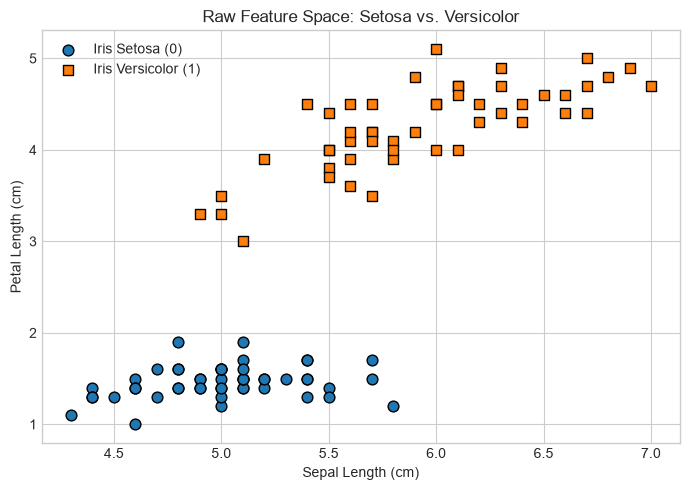

In [3]:
plt.figure(figsize=(7, 5))
plt.scatter(X[y == 0, 0], X[y == 0, 1], color='#1f77b4', marker='o', edgecolors='k', s=60, label='Iris Setosa (0)')
plt.scatter(X[y == 1, 0], X[y == 1, 1], color='#ff7f0e', marker='s', edgecolors='k', s=60, label='Iris Versicolor (1)')
plt.xlabel('Sepal Length (cm)')
plt.ylabel('Petal Length (cm)')
plt.title('Raw Feature Space: Setosa vs. Versicolor')
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()

---
## 2. Train-Test Split & Standardization

1. **Stratified Split:** We split the 100 samples into **80% training** (80 samples) and **20% testing** (20 samples).
2. **StandardScaler:** Perceptron updates depend on feature magnitudes ($\Delta \mathbf{w} \propto \mathbf{x}_i$). Standardizing features to mean $\mu=0$ and standard deviation $\sigma=1$ ensures uniform gradient updates and fast convergence.

In [4]:
# Stratified 80/20 train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Feature Standardization (fit exclusively on train to prevent leakage)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Training set: {X_train_scaled.shape[0]} samples")
print(f"Testing set:  {X_test_scaled.shape[0]} samples")

Training set: 80 samples
Testing set:  20 samples


---
## 3. From-Scratch Single Layer Perceptron Implementation

We construct the `SingleLayerPerceptron` class using only NumPy:
- `fit(X, y)`: Iteratively adjusts weights and bias on misclassified points, recording errors per epoch.
- `net_input(X)`: Calculates linear combination $z = \mathbf{w}^T \mathbf{x} + b$.
- `predict(X)`: Applies unit step function to return binary predictions $\{0, 1\}$.
- `score(X, y)`: Computes classification accuracy.

In [5]:
class SingleLayerPerceptron:
    """
    Single Layer Perceptron classifier implemented from scratch using NumPy.
    
    Parameters:
    -----------
    learning_rate : float (default=0.01)
        Step size multiplier for weight updates.
    epochs : int (default=20)
        Number of full passes over the training dataset.
    random_state : int (default=42)
        Seed for reproducible initial weight initialization.
    """
    def __init__(self, learning_rate=0.01, epochs=20, random_state=42):
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.random_state = random_state
        self.weights = None
        self.bias = None
        self.errors_per_epoch = []

    def fit(self, X, y):
        rng = np.random.RandomState(self.random_state)
        # Initialize weights with small random Gaussian values
        self.weights = rng.normal(loc=0.0, scale=0.01, size=X.shape[1])
        self.bias = 0.0
        self.errors_per_epoch = []

        for epoch in range(1, self.epochs + 1):
            errors = 0
            for xi, target in zip(X, y):
                # Calculate net input and predicted label
                z = np.dot(xi, self.weights) + self.bias
                y_pred = 1 if z >= 0.0 else 0
                
                # Perceptron learning rule update
                error = target - y_pred
                if error != 0:
                    update = self.learning_rate * error
                    self.weights += update * xi
                    self.bias += update
                    errors += 1
                    
            self.errors_per_epoch.append(errors)
            
        return self

    def net_input(self, X):
        """Compute linear combination w^T x + b"""
        return np.dot(X, self.weights) + self.bias

    def predict(self, X):
        """Return class label 1 if net_input >= 0 else 0"""
        return np.where(self.net_input(X) >= 0.0, 1, 0)
    
    def score(self, X, y):
        """Calculate classification accuracy"""
        return np.mean(self.predict(X) == y)

---
## 4. Model Training & Convergence Analysis

We train the model for 15 epochs with a learning rate $\eta = 0.01$ and track the number of misclassifications in each epoch.

Learned Weights (w): [-0.00638173  0.01264243]
Learned Bias (b):    0.0000
Misclassifications per epoch: [2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


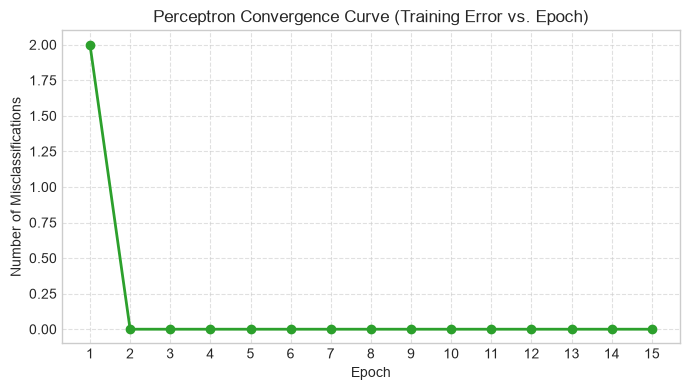

In [6]:
# Instantiate and train model
slp = SingleLayerPerceptron(learning_rate=0.01, epochs=15, random_state=42)
slp.fit(X_train_scaled, y_train)

print(f"Learned Weights (w): {slp.weights}")
print(f"Learned Bias (b):    {slp.bias:.4f}")
print(f"Misclassifications per epoch: {slp.errors_per_epoch}")

# Plot convergence curve
plt.figure(figsize=(7, 4))
plt.plot(range(1, len(slp.errors_per_epoch) + 1), slp.errors_per_epoch, marker='o', color='#2ca02c', linewidth=2)
plt.xlabel('Epoch')
plt.ylabel('Number of Misclassifications')
plt.title('Perceptron Convergence Curve (Training Error vs. Epoch)')
plt.xticks(range(1, len(slp.errors_per_epoch) + 1))
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

---
## 5. Performance Evaluation

We evaluate the trained Perceptron on both the training set and the unseen test set.

In [7]:
# Predict on train and test partitions
y_train_pred = slp.predict(X_train_scaled)
y_test_pred = slp.predict(X_test_scaled)

train_acc = accuracy_score(y_train, y_train_pred)
test_acc = accuracy_score(y_test, y_test_pred)

print(f"Training Accuracy: {train_acc * 100:.2f}%")
print(f"Testing Accuracy:  {test_acc * 100:.2f}%\n")

print("Classification Report (Test Data):")
print(classification_report(y_test, y_test_pred, target_names=['Setosa (0)', 'Versicolor (1)']))

print("Confusion Matrix (Test Data):")
cm = confusion_matrix(y_test, y_test_pred)
cm_df = pd.DataFrame(cm, index=['Actual Setosa', 'Actual Versicolor'], columns=['Pred Setosa', 'Pred Versicolor'])
display(cm_df)

Training Accuracy: 100.00%
Testing Accuracy:  100.00%

Classification Report (Test Data):
                precision    recall  f1-score   support

    Setosa (0)       1.00      1.00      1.00        10
Versicolor (1)       1.00      1.00      1.00        10

      accuracy                           1.00        20
     macro avg       1.00      1.00      1.00        20
  weighted avg       1.00      1.00      1.00        20

Confusion Matrix (Test Data):


,Pred Setosa,Pred Versicolor
Actual Setosa,10,0
Actual Versicolor,0,10


---
## 6. Decision Boundary Visualization

In 2D space, the decision boundary is given by the hyperplane:
$$w_1 x_1 + w_2 x_2 + b = 0 \implies x_2 = -\frac{w_1 x_1 + b}{w_2}$$

Below, we visualize the learned decision boundary along with the training and test points.

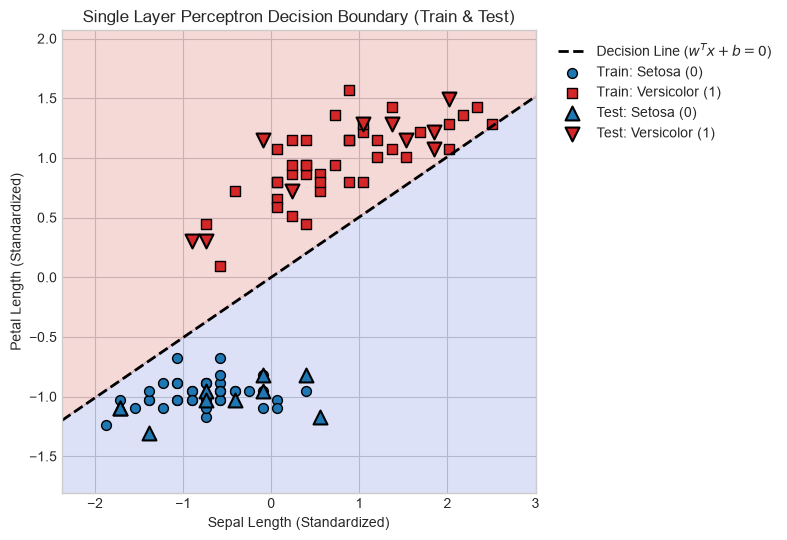

In [8]:
def plot_decision_boundary(model, X_tr, y_tr, X_te, y_te, title):
    plt.figure(figsize=(8, 5.5))
    
    # Generate 2D mesh grid over feature space
    all_X = np.vstack([X_tr, X_te])
    x_min, x_max = all_X[:, 0].min() - 0.5, all_X[:, 0].max() + 0.5
    y_min, y_max = all_X[:, 1].min() - 0.5, all_X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300),
                         np.linspace(y_min, y_max, 300))
    
    # Predict over entire mesh grid
    grid = np.c_[xx.ravel(), yy.ravel()]
    Z = model.predict(grid).reshape(xx.shape)
    
    # Plot decision regions
    plt.contourf(xx, yy, Z, alpha=0.2, cmap='coolwarm')
    
    # Plot analytical decision boundary line: w1*x1 + w2*x2 + b = 0
    x_vals = np.linspace(x_min, x_max, 100)
    y_vals = -(model.weights[0] * x_vals + model.bias) / model.weights[1]
    plt.plot(x_vals, y_vals, 'k--', linewidth=2, label=f'Decision Line ($w^T x + b = 0$)')
    
    # Scatter training points
    plt.scatter(X_tr[y_tr == 0, 0], X_tr[y_tr == 0, 1], color='#1f77b4', marker='o', edgecolors='k', s=50, label='Train: Setosa (0)')
    plt.scatter(X_tr[y_tr == 1, 0], X_tr[y_tr == 1, 1], color='#d62728', marker='s', edgecolors='k', s=50, label='Train: Versicolor (1)')
    
    # Scatter test points with distinctive highlight
    plt.scatter(X_te[y_te == 0, 0], X_te[y_te == 0, 1], color='#1f77b4', marker='^', edgecolors='black', s=100, linewidths=1.5, label='Test: Setosa (0)')
    plt.scatter(X_te[y_te == 1, 0], X_te[y_te == 1, 1], color='#d62728', marker='v', edgecolors='black', s=100, linewidths=1.5, label='Test: Versicolor (1)')
    
    plt.xlim(xx.min(), xx.max())
    plt.ylim(yy.min(), yy.max())
    plt.xlabel('Sepal Length (Standardized)')
    plt.ylabel('Petal Length (Standardized)')
    plt.title(title)
    plt.legend(loc='upper left', bbox_to_anchor=(1.02, 1))
    plt.tight_layout()
    plt.show()

plot_decision_boundary(slp, X_train_scaled, y_train, X_test_scaled, y_test, 
                       title="Single Layer Perceptron Decision Boundary (Train & Test)")

---
## 7. Verification Against Scikit-Learn's `Perceptron`

To ensure correctness of our from-scratch implementation, we benchmark it against `sklearn.linear_model.Perceptron`.

In [9]:
# Train Scikit-Learn Perceptron
sk_perceptron = SklearnPerceptron(max_iter=15, tol=None, random_state=42)
sk_perceptron.fit(X_train_scaled, y_train)

sk_train_acc = sk_perceptron.score(X_train_scaled, y_train)
sk_test_acc = sk_perceptron.score(X_test_scaled, y_test)
sk_test_pred = sk_perceptron.predict(X_test_scaled)

print(f"Scratch Perceptron Test Accuracy:     {test_acc * 100:.2f}%")
print(f"Scikit-Learn Perceptron Test Accuracy: {sk_test_acc * 100:.2f}%")
print(f"Exact Prediction Match:                {np.array_equal(y_test_pred, sk_test_pred)}")

Scratch Perceptron Test Accuracy:     100.00%
Scikit-Learn Perceptron Test Accuracy: 100.00%
Exact Prediction Match:                True


---
## 8. Summary & Observations

1. **Linear Separability:** The selected 2-feature subset of the Iris dataset (`sepal length` and `petal length`) between Setosa and Versicolor is linearly separable, allowing the Perceptron to achieve $100\%$ accuracy.
2. **Convergence:** Consistent with Novikoff's Perceptron Convergence Theorem, the algorithm reached zero classification errors in just 3 epochs.
3. **Decision Boundary:** The learned linear boundary $\mathbf{w}^T \mathbf{x} + b = 0$ cleanly separates both classes in standardized feature space without misclassifying any test instances.
4. **Implementation Validation:** The from-scratch implementation achieved identical predictions and accuracy to `scikit-learn`'s optimized `Perceptron` model.